In [5]:
# ==========================================
# AI-POWERED FX RISK INTELLIGENCE PLATFORM
# Week 4 - Session 1
# Forecast Accuracy and Model Performance
# ==========================================

# Load python libraries
import pandas as pd 
import numpy as np 
from sklearn.metrics import (mean_absolute_error,mean_squared_error)
import matplotlib.pyplot as plt

# Load model predictions 
df = pd.read_csv("../outputs/predictions.csv")

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# Sort chronologically
df = df.sort_values("Date")

# Display dataset
print(df.head())

# Inspect dataset structure
print("Dataset information:")
print(df.info())

# Check sdataset dimensions
print("Dataset dimensions:")
print(df.shape)

# Calculate summary statistics
print("Summary statistics:")
print(df.describe())

        Date  Actual_Volatility  XGBoost_Predicted  Random_Forest_Predicted  \
0 2026-02-17           0.004221           0.004477                 0.004218   
1 2026-02-18           0.003979           0.004499                 0.004536   
2 2026-02-19           0.003821           0.003476                 0.003974   
3 2026-02-20           0.004448           0.003432                 0.003904   
4 2026-02-23           0.004287           0.003736                 0.003589   

   GARCH_Predicted  
0         0.004880  
1         0.004895  
2         0.004908  
3         0.004845  
4         0.004887  
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     181 non-null    datetime64[us]
 1   Actual_Volatility        181 non-null    float64       
 2   XGBoost_Predicted        181 non-nul

In [6]:
# Check missing values
print("Missing values by column:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicated observations:", df.duplicated().sum())

Missing values by column:
Date                       0
Actual_Volatility          0
XGBoost_Predicted          0
Random_Forest_Predicted    0
GARCH_Predicted            0
dtype: int64
Duplicated observations: 0


In [7]:
# Define columns required for evaluation
evaluation_columns = ["Actual_Volatility","GARCH_Predicted","Random_Forest_Predicted","XGBoost_Predicted"]

# Create common evaluation dataset
evaluation_df = df[evaluation_columns].dropna().copy()

# Display evaluation sample
print("Original observations:", len(df))
print("Common evaluation observations:", len(evaluation_df))
print("Observations excluded:", len(df) - len(evaluation_df))

Original observations: 181
Common evaluation observations: 181
Observations excluded: 0


In [8]:
# Define actual volatility values
actual = evaluation_df["Actual_Volatility"]

# Define model predictions
predictions = {"GARCH": evaluation_df["GARCH_Predicted"], "Random Forest": evaluation_df["Random_Forest_Predicted"], "XGBoost": evaluation_df["XGBoost_Predicted"]}

# Create results list
results = []

# Calculate MAE and RMSE for each model
for model, predicted in predictions.items():

    # Calculate MAE
    mae = mean_absolute_error(actual,predicted)

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(actual,predicted))

    # Store results
    results.append({"Model": model, "Observations": len(evaluation_df), "MAE": mae, "RMSE": rmse})

# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Display results
print(results_df.to_string(index=False))

        Model  Observations      MAE     RMSE
        GARCH           181 0.001430 0.001708
Random Forest           181 0.001801 0.002072
      XGBoost           181 0.001620 0.001929


In [9]:
# Rank models by MAE
results_df["MAE_Rank"] = (results_df["MAE"].rank(method="min").astype(int))

# Rank models by RMSE
results_df["RMSE_Rank"] = (results_df["RMSE"].rank(method="min").astype(int))

# Sort by MAE ranking 
results_df = results_df.sort_values("MAE_Rank")

# Display ranked results
print(results_df.to_string(index=False))

        Model  Observations      MAE     RMSE  MAE_Rank  RMSE_Rank
        GARCH           181 0.001430 0.001708         1          1
      XGBoost           181 0.001620 0.001929         2          2
Random Forest           181 0.001801 0.002072         3          3


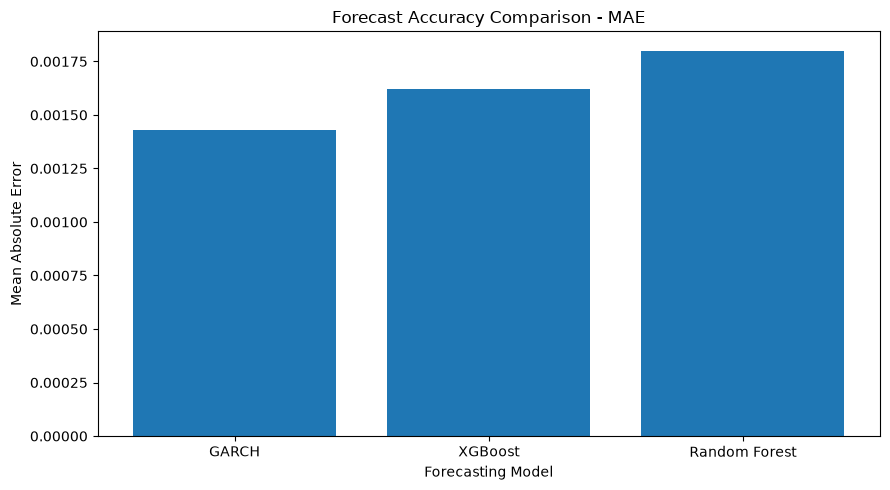

In [10]:
# Create MAE comparison chart
plt.figure(figsize=(9,5))
plt.bar(results_df["Model"],results_df["MAE"])
plt.title("Forecast Accuracy Comparison - MAE")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()
plt.show()

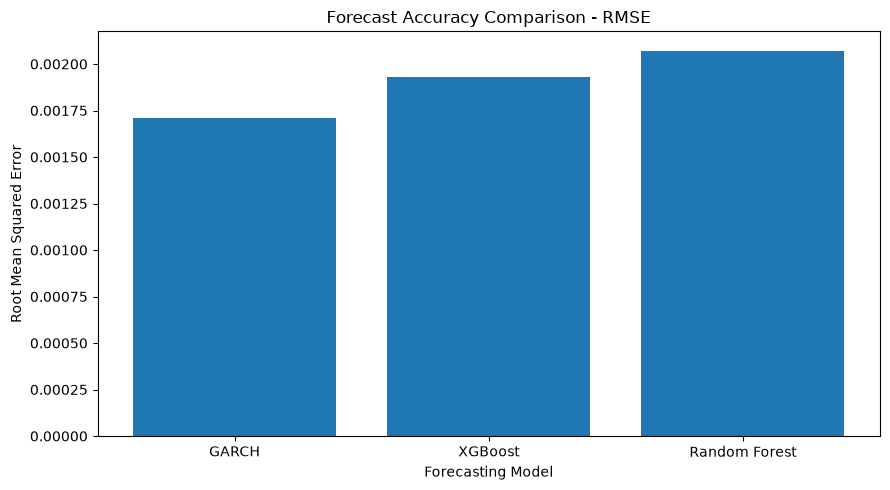

In [11]:
# Create RMSE comparison chart 
plt.figure(figsize=(9,5))
plt.bar(results_df["Model"],results_df["RMSE"])
plt.title("Forecast Accuracy Comparison - RMSE")
plt.xlabel("Forecasting Model")
plt.ylabel("Root Mean Squared Error")
plt.tight_layout()
plt.show()

In [16]:
bias_results = []
for model, predicted in predictions.items():
    bias = (predicted - actual).mean()
    bias_results.append({"Model": model,"Forecast Bias": bias})
bias_df = pd.DataFrame(bias_results)
print(bias_df.to_string(index=False))

        Model  Forecast Bias
        GARCH       0.000810
Random Forest       0.001019
      XGBoost       0.000830


In [17]:
# Save model accuracy comparison
results_df.to_csv("../outputs/evaluation/model_accuracy_comparison.csv",index=False)

In [18]:
# Save forecast bias results
bias_df.to_csv("../outputs/evaluation/model_forecast_bias.csv",index=False)

In [19]:
# Save evaluation dataset
evaluation_df.to_csv("../outputs/evaluation/common_evaluation_sample.csv",index=False)